# 02 – Digester batch analysis (D1–D4)

Reads only `data/batch_master.csv` and `data/lab_linked.csv` (made by `01_build_master.ipynb`) – fast, no PI access.
The order follows `workflow.md`: **baseline quality → Step 1 chips → Step 2 prehydrolysis → Step 3 heat & cook → Step 4 displacement → link to lab**.

Settings at the top: `ONLY_OK_BATCHES` (use only batches with `quality_flag == "ok"`).

In [59]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 80)

from build_master import load_outputs

ONLY_OK_BATCHES = True

master, lab_linked = load_outputs()
if ONLY_OK_BATCHES:
    master = master[master["quality_flag"] == "ok"]
print("Batches:", len(master), "| per digester:", master["digester"].value_counts().sort_index().to_dict())

LAB_LABELS = {"press1_kappa": "Kappa", "press1_viscosity": "Viscosity", "press1_brightness": "Brightness"}


def volatility_table(columns):
    """N, Mean, SD, CV%, Min, Max per digester for each column."""
    rows = []
    for col in columns:
        if col not in master:
            continue
        for dig, vals in master.groupby("digester")[col]:
            vals = vals.dropna()
            rows.append({"Parameter": col, "Digester": f"D{dig}", "N": len(vals), "Mean": vals.mean(),
                         "SD": vals.std(), "CV%": 100 * vals.std() / vals.mean() if vals.mean() else np.nan,
                         "Min": vals.min(), "Max": vals.max()})
    return pd.DataFrame(rows).set_index(["Parameter", "Digester"]).round(2)


def boxplots(columns, title):
    """One boxplot per column, D1-D4 side by side."""
    columns = [c for c in columns if c in master]
    fig, axes = plt.subplots(1, len(columns), figsize=(4.5 * len(columns), 4.5))
    for ax, col in zip(np.atleast_1d(axes), columns):
        sns.boxplot(data=master, x="digester", y=col, ax=ax)
        ax.set_title(col, fontsize=9)
        ax.set_xlabel("Digester")
        ax.set_ylabel("")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Batches: 1463 | per digester: {1: 413, 2: 414, 3: 408, 4: 228}


## Quality map – Kappa vs Viscosity per digester

One scatter per digester (D1–D4) from `master` (1 point = 1 batch). Outliers beyond `SIGMA` sd are dropped per digester, on both axes. Change `X_COL` / `Y_COL` / `SIGMA` to plot other pairs. A `CLUSTER_K` hook is left for a future k-means colouring.

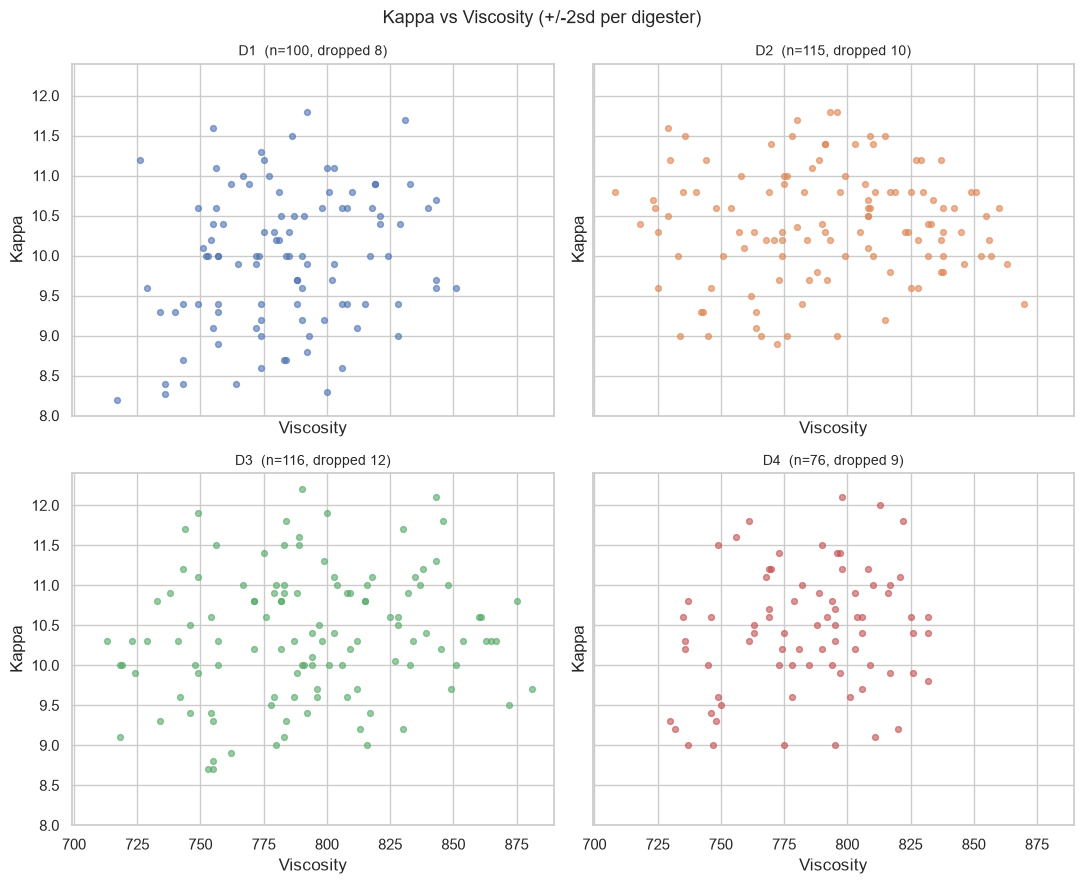

In [60]:
X_COL = "press1_viscosity"        # x axis
Y_COL = "press1_kappa"    # y axis
SIGMA = 2                     # drop points beyond this many sd (per digester)
CLUSTER_K = None              # future: set an int to colour by k-means instead of one colour


def within_sigma(s, sigma=SIGMA):
    """Boolean mask: value within mean +/- sigma*sd (NaN -> False)."""
    m, sd = s.mean(), s.std()
    if not sd:
        return s.notna()
    return (s - m).abs() <= sigma * sd


def quality_scatter(x_col=X_COL, y_col=Y_COL, sigma=SIGMA):
    """2x2 scatter of y vs x, one digester per panel, outliers trimmed per digester."""
    digs = sorted(master["digester"].dropna().unique())
    fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True)
    for ax, dig in zip(axes.ravel(), digs):
        sub = master[master["digester"] == dig][[x_col, y_col]].dropna()
        keep = within_sigma(sub[x_col], sigma) & within_sigma(sub[y_col], sigma)
        sub, n_out = sub[keep], int((~keep).sum())
        ax.scatter(sub[x_col], sub[y_col], s=18, alpha=0.6, color=f"C{int(dig) - 1}")
        ax.set_title(f"D{int(dig)}  (n={len(sub)}, dropped {n_out})", fontsize=10)
        ax.set_xlabel(LAB_LABELS.get(x_col, x_col))
        ax.set_ylabel(LAB_LABELS.get(y_col, y_col))
    for ax in axes.ravel()[len(digs):]:
        ax.set_visible(False)
    fig.suptitle(f"{LAB_LABELS.get(y_col, y_col)} vs {LAB_LABELS.get(x_col, x_col)} (+/-{sigma}sd per digester)", fontsize=13)
    plt.tight_layout()
    plt.show()


quality_scatter()

## Process values by quality grade, per digester

For each digester, split the batches by their lab grade (`low` / `normal` / `high`) and show the typical value of each process parameter in that group. The value is `median (Q1–Q3)` so outliers do not shift it; the `n` row is the batch count per group. Compare the `normal` column across parameters to read off "when quality is normal, this parameter sits around here".

Change `GRADE_COL` (`viscosity_grade` / `kappa_grade`) or `PARAMS` to look at other targets or sensors. Grades are provisional (`config.QUALITY_TARGETS`). `normal` groups are small, so treat this as a hypothesis, not a confirmed setpoint.

In [61]:
GRADE_COL = "viscosity_grade"     # viscosity_grade or kappa_grade
GRADE_ORDER = ["low", "normal", "high"]
PARAMS = [                         # workflow X parameters to profile (edit freely)
    "h_factor",
    "white_liquor_m3",
    "white_liquor_per_ton_chip",
    "liquor_to_wood_ratio",
    "chip_weight_max_chip_filling",
    "circulation_temp_max_heat_and_cook",
    "digester_pressure_mean_heat_and_cook",
    "steam_to_heater_flow_mean_heat_and_cook",
    "steam_heater_temp_max_heat_and_cook",
    "alkali_accumulator1_conc_mean_hot_liquor_filling",
    "alkali_accumulator2_conc_mean_hot_liquor_filling",
    "black_liquor_conductivity_mean_displacement",
    "pfactor_actual_last_prehydrolysis",
    "pfactor_setpoint_last_prehydrolysis",
    "hbl_accumulator_cond_mean_hot_liquor_filling",

]


def _cell(s):
    """median (Q1-Q3) of a series, or '-' if empty."""
    s = s.dropna()
    if s.empty:
        return "-"
    return f"{s.median():.1f} ({s.quantile(.25):.1f}\u2013{s.quantile(.75):.1f})"


def grade_summary(dig, grade_col=GRADE_COL, params=PARAMS):
    """One digester: rows = params, columns = grade groups, value = median (Q1-Q3)."""
    sub = master[(master["digester"] == dig) & master[grade_col].notna()]
    cols = [g for g in GRADE_ORDER if g in sub[grade_col].unique()]
    rows = {p: {g: _cell(sub[sub[grade_col] == g][p]) for g in cols}
            for p in params if p in sub.columns}
    table = pd.DataFrame(rows).T
    table.loc["n (batches)"] = {g: int((sub[grade_col] == g).sum()) for g in cols}
    return table


for dig in sorted(master["digester"].dropna().unique()):
    print(f"\n=== D{int(dig)} — process values by {GRADE_COL} ===")
    display(grade_summary(dig))


=== D1 — process values by viscosity_grade ===


,low,normal,high
h_factor,505.2 (505.2–505.2),514.0 (467.5–550.9),475.5 (457.7–519.0)
white_liquor_m3,13.0 (13.0–13.0),13.1 (12.9–14.1),12.9 (12.8–14.4)
white_liquor_per_ton_chip,0.1 (0.1–0.1),0.1 (0.1–0.2),0.1 (0.1–0.2)
liquor_to_wood_ratio,1.5 (1.5–1.5),1.5 (1.5–1.6),1.4 (1.4–1.5)
chip_weight_max_chip_filling,93.1 (93.1–93.1),91.9 (89.0–95.2),95.7 (92.7–98.4)
circulation_temp_max_heat_and_cook,158.8 (158.8–158.8),157.3 (156.4–158.4),156.8 (156.0–157.9)
digester_pressure_mean_heat_and_cook,6.1 (6.1–6.1),6.2 (6.1–6.2),6.1 (6.1–6.2)
steam_to_heater_flow_mean_heat_and_cook,5.7 (5.7–5.7),3.5 (1.1–6.0),2.2 (-1.1–4.6)
steam_heater_temp_max_heat_and_cook,162.5 (162.5–162.5),162.9 (162.3–163.6),163.0 (162.6–163.7)
alkali_accumulator1_conc_mean_hot_liquor_filling,37.7 (37.7–37.7),36.6 (36.1–37.2),36.1 (35.9–36.7)



=== D2 — process values by viscosity_grade ===


,low,normal,high
h_factor,334.2 (326.0–337.8),338.1 (315.7–400.7),323.4 (307.9–352.4)
white_liquor_m3,12.0 (11.9–14.0),13.0 (12.9–14.0),12.9 (12.8–13.1)
white_liquor_per_ton_chip,0.1 (0.1–0.1),0.1 (0.1–0.1),0.1 (0.1–0.1)
liquor_to_wood_ratio,1.4 (1.3–1.4),1.4 (1.4–1.6),1.5 (1.4–1.6)
chip_weight_max_chip_filling,95.5 (95.1–101.7),95.0 (90.7–99.3),93.6 (89.4–96.0)
circulation_temp_max_heat_and_cook,158.6 (157.8–159.3),159.1 (158.4–159.9),159.2 (158.6–159.8)
digester_pressure_mean_heat_and_cook,6.2 (6.2–6.2),6.1 (6.0–6.2),6.2 (6.1–6.3)
steam_to_heater_flow_mean_heat_and_cook,3.3 (3.2–4.1),2.7 (2.0–3.3),2.9 (2.2–3.8)
steam_heater_temp_max_heat_and_cook,163.0 (162.0–163.0),161.4 (160.5–162.4),161.7 (161.0–162.1)
alkali_accumulator1_conc_mean_hot_liquor_filling,36.6 (36.0–36.8),37.0 (36.5–37.5),36.0 (35.8–36.5)



=== D3 — process values by viscosity_grade ===


,low,normal,high
h_factor,293.7 (275.2–388.6),312.7 (288.3–340.4),298.8 (276.1–319.4)
white_liquor_m3,16.0 (15.2–18.0),14.0 (12.9–14.3),13.0 (12.8–14.0)
white_liquor_per_ton_chip,0.2 (0.2–0.2),0.2 (0.2–0.2),0.2 (0.1–0.2)
liquor_to_wood_ratio,1.6 (1.5–1.8),1.8 (1.6–1.9),1.8 (1.7–1.9)
chip_weight_max_chip_filling,91.9 (87.2–94.3),86.1 (83.1–89.2),85.6 (81.7–88.2)
circulation_temp_max_heat_and_cook,157.9 (157.9–158.5),157.6 (156.6–158.6),157.7 (156.9–158.5)
digester_pressure_mean_heat_and_cook,5.9 (5.7–6.0),5.9 (5.7–6.2),5.9 (5.7–6.1)
steam_to_heater_flow_mean_heat_and_cook,1.8 (0.7–2.6),1.4 (0.5–2.1),1.4 (-0.0–2.1)
steam_heater_temp_max_heat_and_cook,160.9 (159.4–161.5),160.0 (156.9–161.1),158.8 (156.9–159.8)
alkali_accumulator1_conc_mean_hot_liquor_filling,36.9 (36.0–37.9),37.1 (36.4–37.3),36.1 (36.0–37.1)



=== D4 — process values by viscosity_grade ===


,low,normal,high
h_factor,380.7 (323.5–519.4),423.2 (349.5–533.5),353.9 (274.4–407.0)
white_liquor_m3,16.4 (13.7–19.9),13.0 (12.9–14.0),12.9 (12.8–13.9)
white_liquor_per_ton_chip,0.2 (0.2–0.2),0.2 (0.2–0.2),0.2 (0.2–0.2)
liquor_to_wood_ratio,1.5 (1.4–1.5),1.6 (1.5–1.7),1.6 (1.5–1.7)
chip_weight_max_chip_filling,75.0 (74.8–78.7),71.9 (68.7–74.5),71.2 (68.8–73.7)
circulation_temp_max_heat_and_cook,158.5 (157.9–158.9),158.9 (158.2–159.8),158.2 (157.9–158.8)
digester_pressure_mean_heat_and_cook,6.3 (6.3–6.3),6.2 (6.1–6.3),6.2 (6.1–6.3)
steam_to_heater_flow_mean_heat_and_cook,20.9 (20.9–21.0),21.0 (20.9–21.0),21.0 (21.0–21.0)
steam_heater_temp_max_heat_and_cook,162.4 (161.9–162.9),162.4 (160.9–163.0),161.9 (161.5–162.7)
alkali_accumulator1_conc_mean_hot_liquor_filling,38.0 (37.9–38.0),37.1 (36.4–37.7),36.4 (36.0–36.6)


### Process values by combined Kappa+Viscosity grade

`overall_grade` = **normal** only when Kappa *and* Viscosity are both `normal`; otherwise **abnormal**. If either grade is missing the batch is dropped (NaN). Same median (Q1–Q3) layout, one table per digester. `normal` count is small because both targets must land together — treat as a hypothesis, not a conclusion.

In [62]:
OVERALL_ORDER = ["abnormal", "normal"]   # overall_grade comes from build_master (normal only if every target is normal)


def overall_summary(dig, params=PARAMS):
    """One digester: rows = params, columns = abnormal/normal, value = median (Q1-Q3)."""
    sub = master[(master["digester"] == dig) & master["overall_grade"].notna()]
    cols = [g for g in OVERALL_ORDER if g in sub["overall_grade"].unique()]
    rows = {p: {g: _cell(sub[sub["overall_grade"] == g][p]) for g in cols}
            for p in params if p in sub.columns}
    table = pd.DataFrame(rows).T
    table.loc["n (batches)"] = {g: int((sub["overall_grade"] == g).sum()) for g in cols}
    return table


for dig in sorted(master["digester"].dropna().unique()):
    print(f"\n=== D{int(dig)} — process values by overall_grade (Kappa+Viscosity) ===")
    
    display(overall_summary(dig))


=== D1 — process values by overall_grade (Kappa+Viscosity) ===


,abnormal,normal
h_factor,502.3 (466.3–536.9),510.6 (455.1–550.2)
white_liquor_m3,13.0 (12.8–14.1),13.1 (12.9–14.1)
white_liquor_per_ton_chip,0.1 (0.1–0.2),0.1 (0.1–0.2)
liquor_to_wood_ratio,1.5 (1.4–1.6),1.6 (1.5–1.6)
chip_weight_max_chip_filling,93.7 (90.1–97.6),91.3 (87.1–94.9)
circulation_temp_max_heat_and_cook,157.1 (156.2–158.1),157.3 (156.2–158.2)
digester_pressure_mean_heat_and_cook,6.2 (6.1–6.2),6.2 (6.1–6.2)
steam_to_heater_flow_mean_heat_and_cook,3.0 (-0.5–5.8),2.8 (0.9–5.9)
steam_heater_temp_max_heat_and_cook,163.0 (162.4–163.5),163.1 (162.7–163.6)
alkali_accumulator1_conc_mean_hot_liquor_filling,36.6 (36.1–37.2),36.4 (35.9–37.0)



=== D2 — process values by overall_grade (Kappa+Viscosity) ===


,abnormal,normal
h_factor,331.7 (314.1–389.3),333.7 (303.6–388.8)
white_liquor_m3,12.9 (12.8–13.6),13.2 (12.9–14.0)
white_liquor_per_ton_chip,0.1 (0.1–0.1),0.1 (0.1–0.2)
liquor_to_wood_ratio,1.5 (1.4–1.6),1.5 (1.4–1.5)
chip_weight_max_chip_filling,94.0 (89.6–96.9),95.0 (92.4–96.9)
circulation_temp_max_heat_and_cook,159.1 (158.4–159.8),159.3 (158.7–159.9)
digester_pressure_mean_heat_and_cook,6.2 (6.1–6.3),6.2 (6.1–6.3)
steam_to_heater_flow_mean_heat_and_cook,2.9 (2.1–3.6),2.7 (1.7–3.9)
steam_heater_temp_max_heat_and_cook,161.6 (160.8–162.3),161.5 (160.6–162.3)
alkali_accumulator1_conc_mean_hot_liquor_filling,36.5 (36.0–37.1),36.8 (36.5–37.4)



=== D3 — process values by overall_grade (Kappa+Viscosity) ===


,abnormal,normal
h_factor,303.6 (280.5–321.1),322.0 (288.7–342.4)
white_liquor_m3,13.1 (12.8–14.1),13.7 (12.9–14.3)
white_liquor_per_ton_chip,0.2 (0.1–0.2),0.2 (0.2–0.2)
liquor_to_wood_ratio,1.8 (1.7–1.9),1.8 (1.6–1.9)
chip_weight_max_chip_filling,86.5 (82.8–88.8),84.1 (81.5–91.8)
circulation_temp_max_heat_and_cook,157.7 (156.9–158.6),157.5 (156.4–158.5)
digester_pressure_mean_heat_and_cook,5.9 (5.7–6.2),6.0 (5.6–6.4)
steam_to_heater_flow_mean_heat_and_cook,1.4 (0.0–2.3),1.4 (0.4–1.9)
steam_heater_temp_max_heat_and_cook,159.1 (156.9–160.9),159.6 (157.0–161.0)
alkali_accumulator1_conc_mean_hot_liquor_filling,36.5 (36.0–37.2),37.2 (36.6–37.3)



=== D4 — process values by overall_grade (Kappa+Viscosity) ===


,abnormal,normal
h_factor,396.5 (305.4–480.9),414.6 (339.8–523.3)
white_liquor_m3,13.0 (12.9–14.1),13.1 (12.9–13.9)
white_liquor_per_ton_chip,0.2 (0.2–0.2),0.2 (0.2–0.2)
liquor_to_wood_ratio,1.6 (1.5–1.7),1.6 (1.5–1.7)
chip_weight_max_chip_filling,72.1 (68.9–74.8),71.6 (68.3–72.7)
circulation_temp_max_heat_and_cook,158.5 (157.9–159.4),158.9 (158.2–159.4)
digester_pressure_mean_heat_and_cook,6.2 (6.1–6.3),6.2 (6.1–6.2)
steam_to_heater_flow_mean_heat_and_cook,21.0 (20.9–21.0),21.0 (21.0–21.0)
steam_heater_temp_max_heat_and_cook,162.0 (161.4–162.9),161.4 (160.9–162.9)
alkali_accumulator1_conc_mean_hot_liquor_filling,36.9 (36.2–37.5),36.9 (36.3–37.7)


## Correlation: lab quality vs process parameters, per digester

Spearman rank correlation between the 3 Press 1 lab values (rows) and the process parameters (columns), one heatmap per digester. 
Red = positive, blue = negative. Only pairs with at least `MIN_N` batches are scored.

Add or drop parameters by editing `PARAMS`. **Note:** these come from lab-linked batch values with no lag/production adjustment, so they are *hypotheses*, not findings.

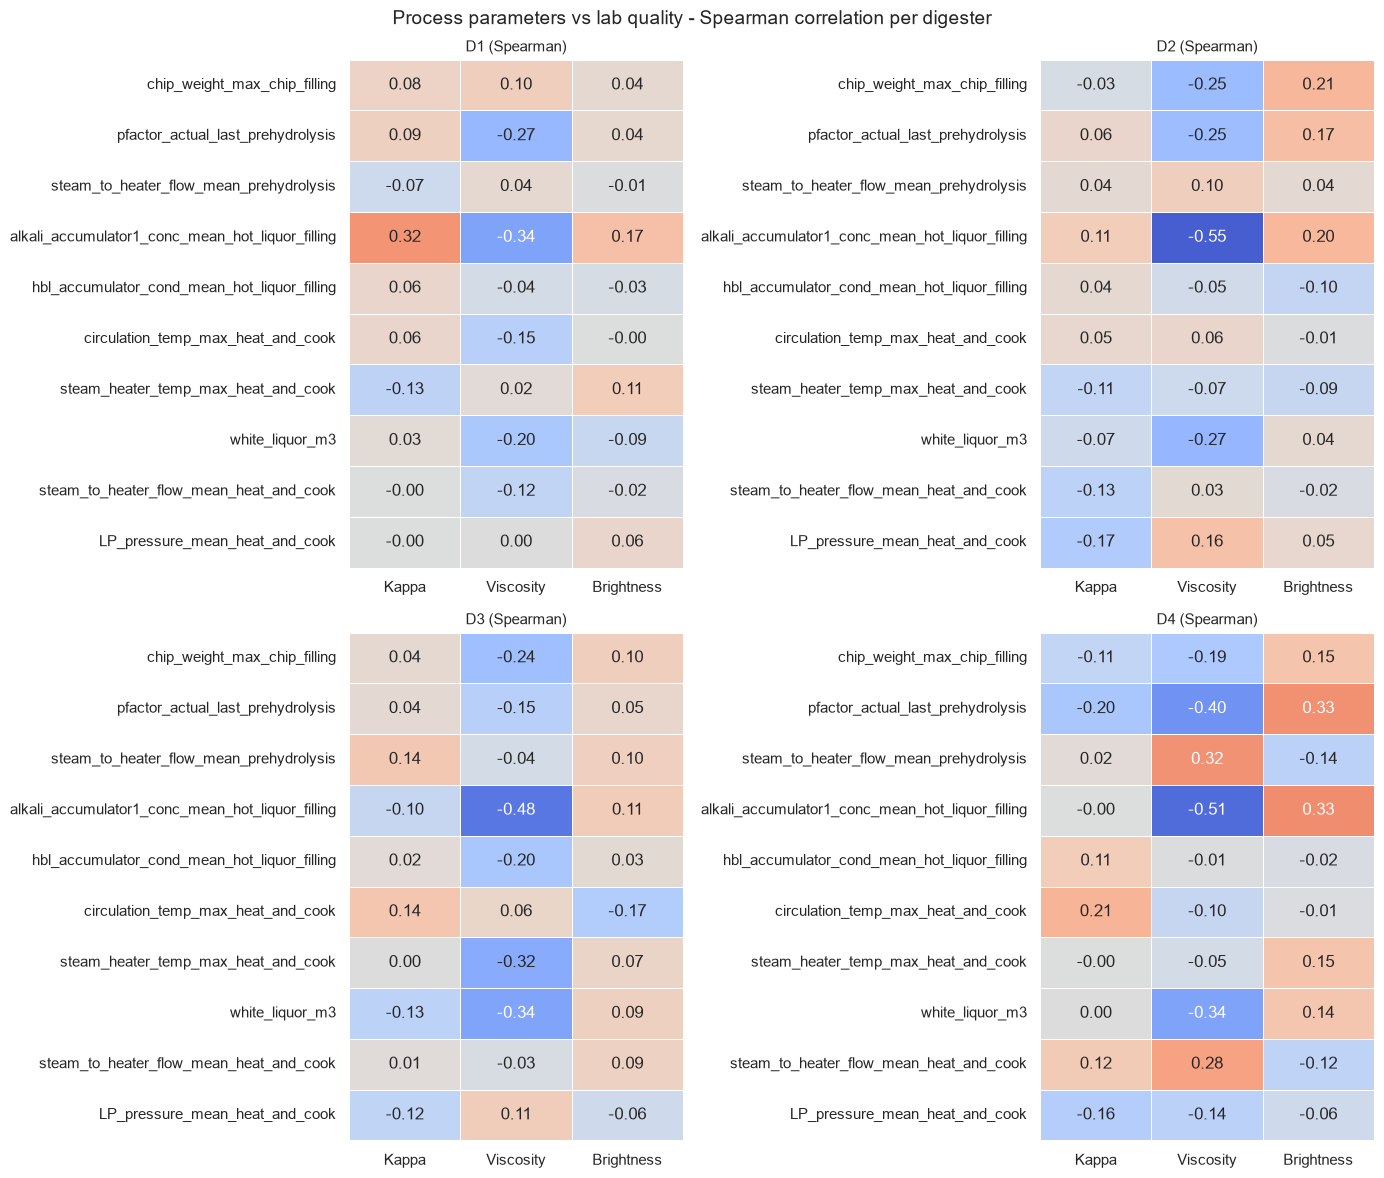

In [63]:
from scipy.stats import spearmanr

MIN_N = 5                                  # skip a pair with fewer batches
LAB_COLS = ["press1_kappa", "press1_viscosity", "press1_brightness"]   # x axis
PARAMS = [                                 # y axis - edit freely
    "chip_weight_max_chip_filling",
    "pfactor_actual_last_prehydrolysis",
    "steam_to_heater_flow_mean_prehydrolysis",
    "alkali_accumulator1_conc_mean_hot_liquor_filling",
    "hbl_accumulator_cond_mean_hot_liquor_filling",
    "circulation_temp_max_heat_and_cook",
    "steam_heater_temp_max_heat_and_cook",
    "white_liquor_m3",
    "steam_to_heater_flow_mean_heat_and_cook",
    "LP_pressure_mean_heat_and_cook",
    "LP_pressure_mean_prehydrolysis"
]
PARAMS = [p for p in PARAMS if p in master.columns]


def corr_matrix(dig):
    d = master[master["digester"] == dig]
    out = pd.DataFrame(index=PARAMS, columns=LAB_COLS, dtype=float)
    for p in PARAMS:
        for lab in LAB_COLS:
            pair = d[[p, lab]].dropna()
            if len(pair) >= MIN_N:
                out.loc[p, lab] = spearmanr(pair[p], pair[lab])[0]
    return out.astype(float)


fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, dig in zip(axes.flatten(), sorted(master["digester"].dropna().unique())):
    m = corr_matrix(dig)
    sns.heatmap(m, 
                annot=True, 
                fmt=".2f", 
                cmap="coolwarm", 
                center=0, 
                vmin=-0.6, 
                vmax=0.6,
                cbar=False, 
                linewidths=0.5, 
                ax=ax,
                xticklabels=[LAB_LABELS[c] for c in m.columns])
    ax.set_title(f"D{int(dig)} (Spearman)", fontsize=11)
    ax.set_ylabel("")
fig.suptitle("Process parameters vs lab quality - Spearman correlation per digester", fontsize=14)
plt.tight_layout()
plt.show()

## Phase 1 – Baseline: Press 1 lab quality per digester

Real lab samples only. Green band = SOP (`config.LAB_SOP_LIMITS`, **not yet confirmed**).

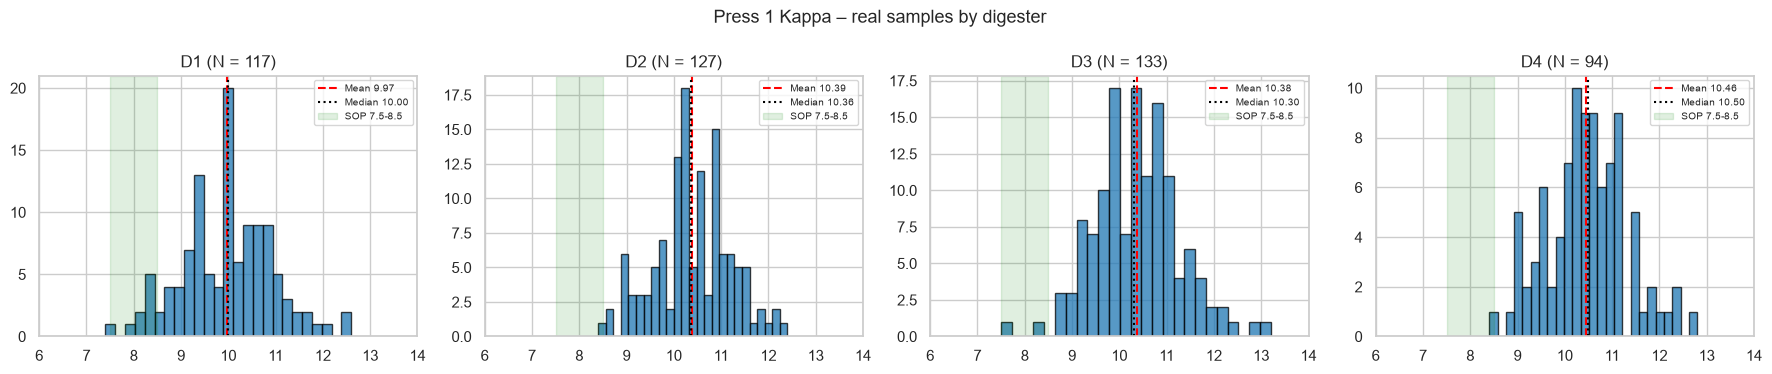

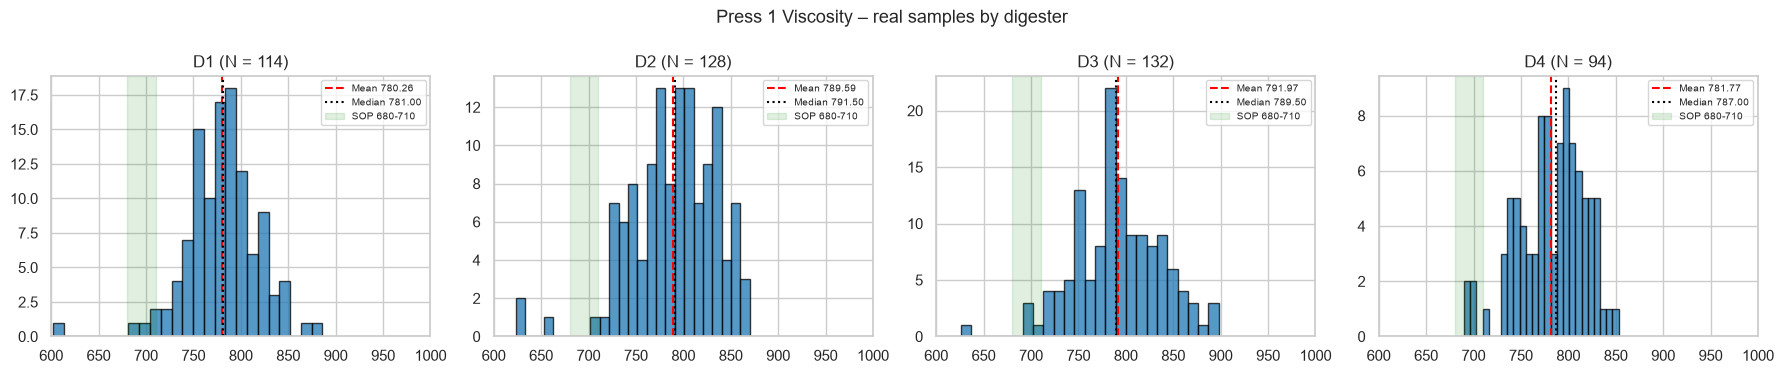

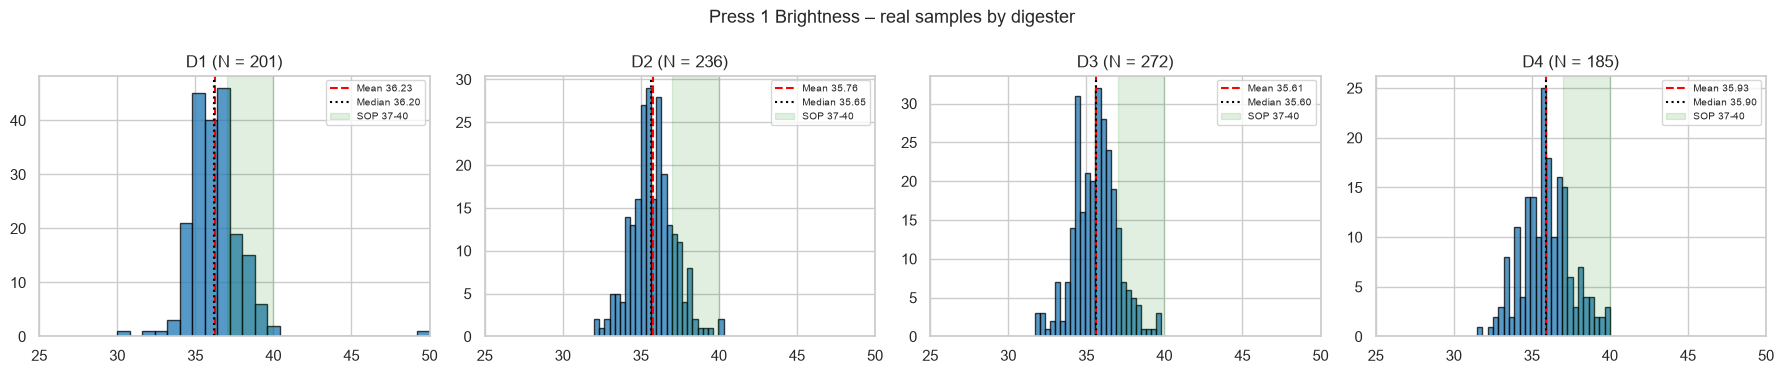

N    Mean  Median     SD
parameter         digester                            
press1_brightness 1         201   36.23   36.20   1.73
                  2         236   35.76   35.65   1.38
                  3         272   35.61   35.60   1.40
                  4         185   35.93   35.90   1.60
press1_kappa      1         117    9.97   10.00   0.97
                  2         127   10.39   10.36   0.80
                  3         133   10.38   10.30   0.91
                  4          94   10.46   10.50   0.85
press1_viscosity  1         114  780.26  781.00  38.41
                  2         128  789.59  791.50  45.49
                  3         132  791.97  789.50  45.72
                  4          94  781.77  787.00  35.39

In [64]:
HIST_XLIM = {"press1_kappa": (6, 14), "press1_viscosity": (600, 1000), "press1_brightness": (25, 50)}

for param, label in LAB_LABELS.items():
    data = lab_linked[lab_linked["parameter"] == param]
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharex=True)
    for ax, dig in zip(axes, [1, 2, 3, 4]):
        vals = data.loc[data["digester"] == dig, "value"].dropna()
        ax.hist(vals, bins=25, color="#1f77b4", edgecolor="black", alpha=0.75)
        ax.axvline(vals.mean(), color="red", linestyle="--", label=f"Mean {vals.mean():.2f}")
        ax.axvline(vals.median(), color="black", linestyle=":", label=f"Median {vals.median():.2f}")
        lo, hi = config.LAB_SOP_LIMITS[param]
        ax.axvspan(lo, hi, color="green", alpha=0.12, label=f"SOP {lo}-{hi}")
        ax.set_xlim(HIST_XLIM[param])
        ax.set_title(f"D{dig} (N = {len(vals)})")
        ax.legend(fontsize=7)
    fig.suptitle(f"Press 1 {label} – real samples by digester", fontsize=13)
    plt.tight_layout()
    plt.show()

summary = (lab_linked.groupby(["parameter", "digester"])["value"]
           .agg(N="count", Mean="mean", Median="median", SD="std").round(2))
display(summary)

### Lab trend over time (24 h rolling mean)

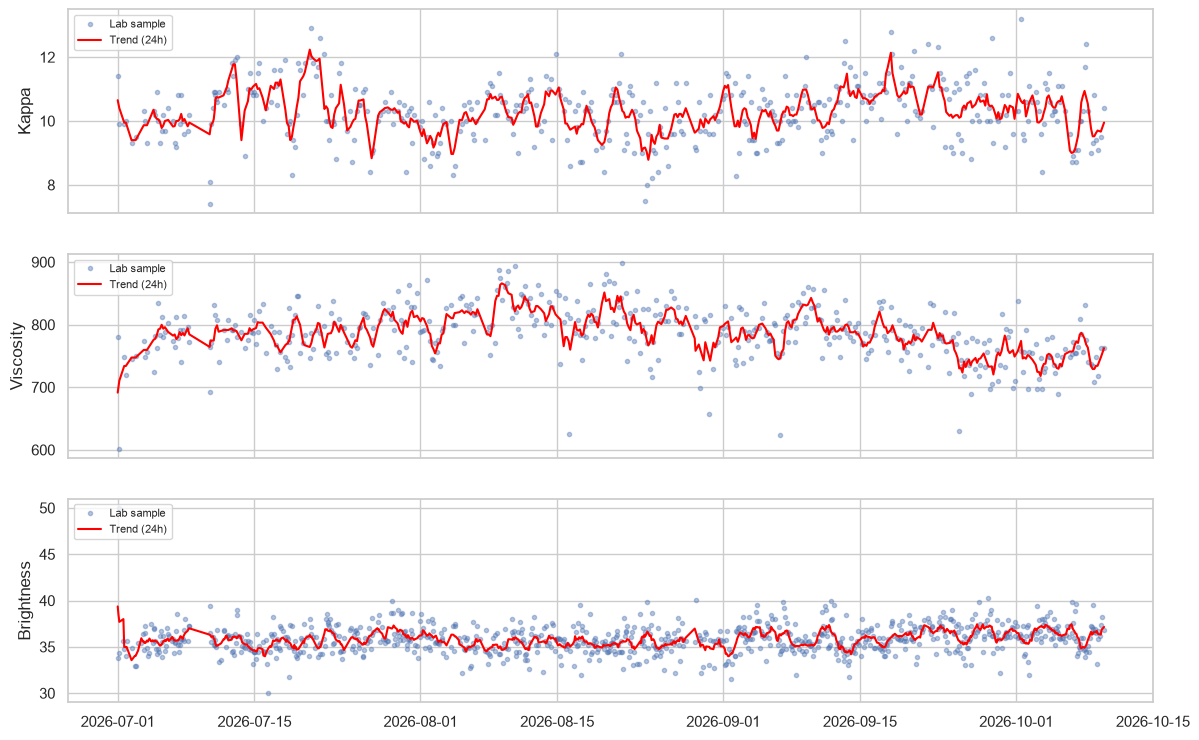

In [65]:
TREND_WINDOW = "24h"

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, (param, label) in zip(axes, LAB_LABELS.items()):
    s = (lab_linked[lab_linked["parameter"] == param]
         .drop_duplicates("timestamp").set_index("timestamp")["value"].sort_index().dropna())
    ax.plot(s.index, s, ".", alpha=0.4, label="Lab sample")
    ax.plot(s.index, s.rolling(TREND_WINDOW, center=True, min_periods=1).mean(), color="red",
            label=f"Trend ({TREND_WINDOW})")
    ax.set_ylabel(label)
    ax.legend(fontsize=8, loc="upper left")
plt.show()

## Step 1 – Input & preparation (chips)

- `chip_weight_max_chip_filling` – chips loaded (wet weight, ton; chip moisture tag is not usable)
- `liquor_to_wood_ratio` – liquor added per ton of wet chips (approximate L:W)
- `white_liquor_m3`, `white_liquor_per_ton_chip` – white liquor added in HOT LIQUOR FILLING, and per ton of wet chips (same recipe volume + fewer chips = more alkali per ton)
- `ventilation_temp_max_chip_filling`, `chip_filling_minutes`

N   Mean     SD    CV%    Min  \
Parameter                         Digester                                    
chip_weight_max_chip_filling      D1        413  92.72   5.91   6.37  70.20   
                                  D2        414  93.73   5.58   5.95  74.94   
                                  D3        408  86.19   6.87   7.97  59.72   
                                  D4        228  71.53   5.11   7.14  50.01   
liquor_to_wood_ratio              D1        413   1.53   0.16  10.71   1.02   
                                  D2        414   1.48   0.15  10.01   1.11   
                                  D3        408   1.80   0.24  13.28   1.26   
                                  D4        228   1.60   0.20  12.50   1.09   
white_liquor_m3                   D1        413  13.72   1.73  12.57  10.20   
                                  D2        414  13.34   1.35  10.08  10.11   
                                  D3        408  13.80   1.77  12.85  11.75   
                                  D4        228  13.78   1.81  13.14  11.84   
white_liquor_per_ton_chip         D1        413   0.15   0.02  14.34   0.10   
                                  D2        414   0.14   0.02  11.38   0.10   
                                  D3        408   0.16   0.02  14.24   0.12   
                                  D4        228   0.19   0.03  14.00   0.15   
ventilation_temp_max_chip_filling D1        413  90.61   2.19   2.42  85.00   
                                  D2        414  93.66   2.42   2.58  86.46   
                                  D3        408  91.76   3.57   3.89  79.58   
                                  D4        228  89.99   1.70   1.89  75.66   
chip_filling_minutes              D1        413  35.02   7.92  22.62  25.00   
                                  D2        414  37.00  13.20  35.66  20.00   
                                  D3        408  35.27  19.35  54.85   5.00   
                                  D4        228  34.80   7.43  21.34  10.00   

                                               Max  
Parameter                         Digester          
chip_weight_max_chip_filling      D1        115.25  
                                  D2        110.59  
                                  D3        106.99  
                                  D4         89.11  
liquor_to_wood_ratio              D1          2.34  
                                  D2          2.08  
                                  D3          3.02  
                                  D4          2.66  
white_liquor_m3                   D1         22.09  
                                  D2         22.93  
                                  D3         24.94  
                                  D4         24.92  
white_liquor_per_ton_chip         D1          0.25  
                                  D2          0.24  
                                  D3          0.30  
                                  D4          0.33  
ventilation_temp_max_chip_filling D1        105.92  
                                  D2        100.53  
                                  D3        128.28  
                                  D4         97.61  
chip_filling_minutes              D1        110.00  
                                  D2        235.00  
                                  D3        385.00  
                                  D4         80.00

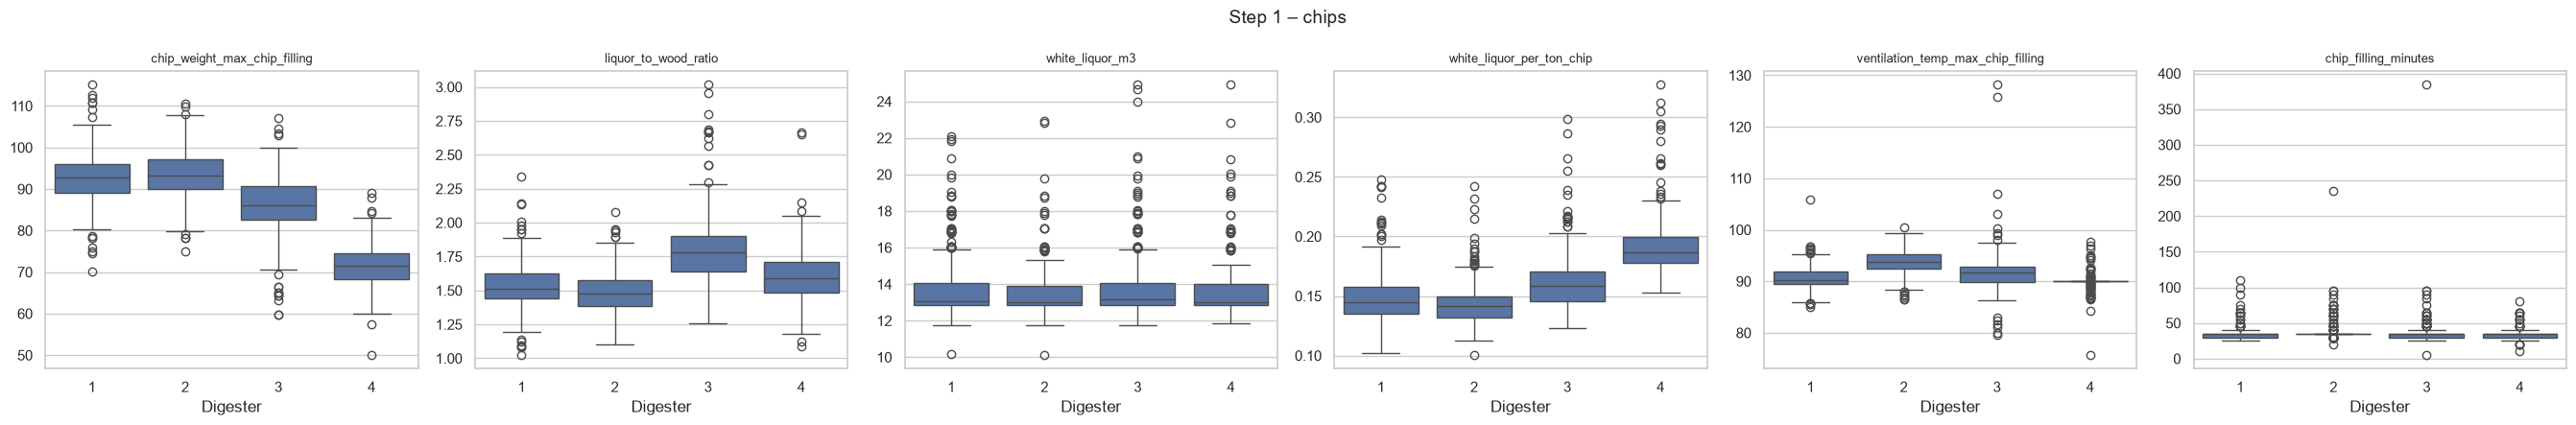

In [66]:
STEP1 = ["chip_weight_max_chip_filling", "liquor_to_wood_ratio",
         "white_liquor_m3", "white_liquor_per_ton_chip", "ventilation_temp_max_chip_filling", "chip_filling_minutes"]
display(volatility_table(STEP1))
boxplots(STEP1, "Step 1 – chips")

## Step 2 – Prehydrolysis

- `pfactor_actual_last_prehydrolysis` vs `pfactor_setpoint_last_prehydrolysis`; `pfactor_gap` = actual − setpoint
- `digester_pressure_max_prehydrolysis`, `prehydrolysis_minutes`

N    Mean     SD    CV%  \
Parameter                           Digester                              
pfactor_actual_last_prehydrolysis   D1        413  336.09  34.03  10.13   
                                    D2        414  342.67  34.11   9.95   
                                    D3        408  342.80  31.97   9.32   
                                    D4        228  356.57  34.98   9.81   
pfactor_setpoint_last_prehydrolysis D1        413  360.22  31.81   8.83   
                                    D2        414  360.39  31.74   8.81   
                                    D3        408  360.29  31.97   8.87   
                                    D4        228  374.96  33.67   8.98   
pfactor_gap                         D1        413  -24.13  14.94 -61.91   
                                    D2        414  -17.72  16.06 -90.67   
                                    D3        408  -17.50  12.62 -72.10   
                                    D4        228  -18.39  10.99 -59.74   
digester_pressure_max_prehydrolysis D1        413    8.32   0.44   5.30   
                                    D2        414    8.31   0.26   3.17   
                                    D3        408    8.32   0.32   3.82   
                                    D4        228    8.02   0.50   6.23   
prehydrolysis_minutes               D1        413   76.90  10.01  13.02   
                                    D2        414   81.80   9.71  11.87   
                                    D3        408   80.29  11.50  14.33   
                                    D4        228   87.15   9.64  11.06   

                                                 Min     Max  
Parameter                           Digester                  
pfactor_actual_last_prehydrolysis   D1        259.05  430.34  
                                    D2        273.64  509.53  
                                    D3        269.25  444.64  
                                    D4        259.15  435.42  
pfactor_setpoint_last_prehydrolysis D1        310.00  450.00  
                                    D2        320.00  450.00  
                                    D3        320.00  450.00  
                                    D4        320.00  450.00  
pfactor_gap                         D1        -59.65    1.59  
                                    D2        -72.84  189.53  
                                    D3        -50.75    0.64  
                                    D4        -60.85    0.04  
digester_pressure_max_prehydrolysis D1          7.10   11.06  
                                    D2          7.12   10.71  
                                    D3          7.05   10.14  
                                    D4          7.15    9.03  
prehydrolysis_minutes               D1         60.00  150.00  
                                    D2         55.00  120.00  
                                    D3         65.00  270.00  
                                    D4         65.00  115.00

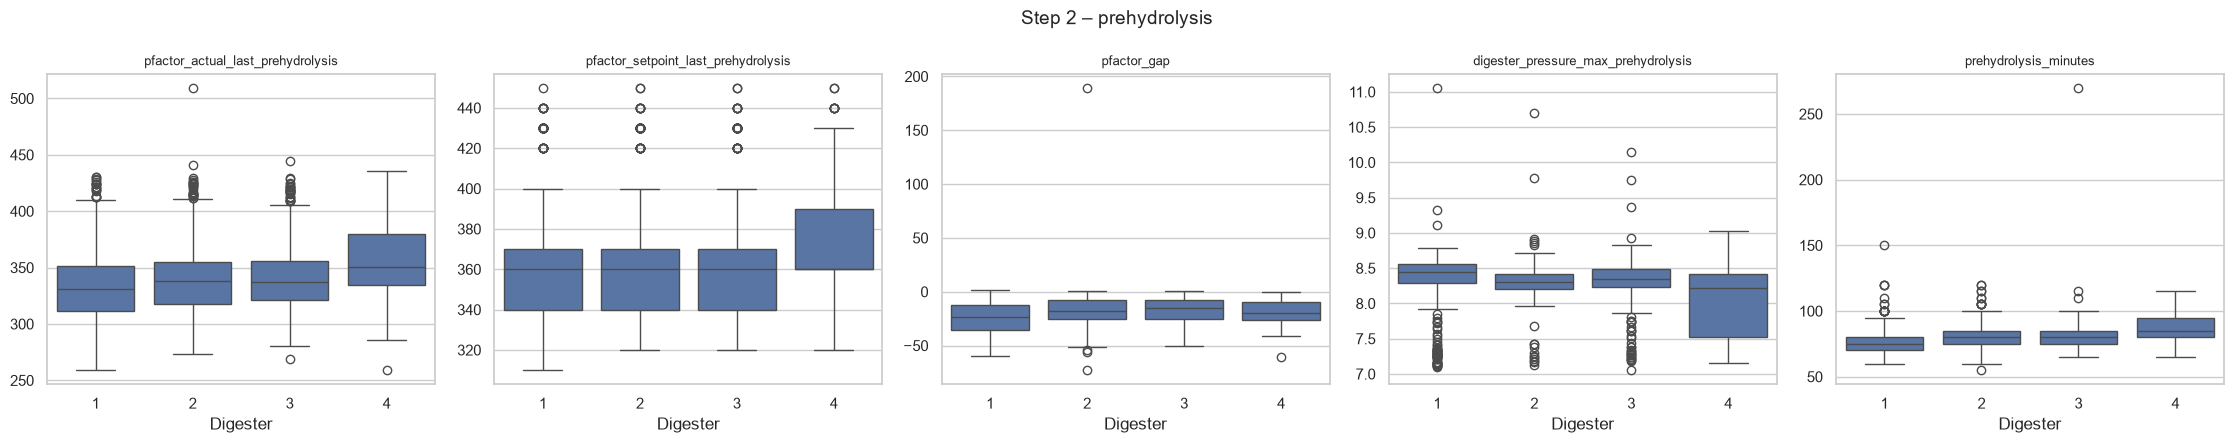

In [67]:
STEP2 = ["pfactor_actual_last_prehydrolysis", "pfactor_setpoint_last_prehydrolysis", "pfactor_gap",
         "digester_pressure_max_prehydrolysis", "prehydrolysis_minutes"]
display(volatility_table(STEP2))
boxplots(STEP2, "Step 2 – prehydrolysis")

## Step 3 – Heat & cook

- `h_factor` (phases in `config.H_FACTOR_PHASES`) and `h_heat_and_cook` (HEAT&COOK only, for comparison)
- temperatures, steam, pressure, and circulation health (screen ΔP, pump current)

N    Mean      SD  \
Parameter                                   Digester                        
h_factor                                    D1        413  513.13   79.39   
                                            D2        414  373.22  131.62   
                                            D3        408  314.35   57.11   
                                            D4        228  412.91  133.47   
h_heat_and_cook                             D1        413  160.85   20.86   
                                            D2        414  168.28   18.87   
                                            D3        408  169.58   13.84   
                                            D4        228  170.58   16.85   
circulation_temp_max_heat_and_cook          D1        413  157.42    1.53   
                                            D2        414  159.16    1.05   
                                            D3        408  157.59    1.48   
                                            D4        228  158.70    1.22   
heat_and_cook_minutes                       D1        413   37.31    5.22   
                                            D2        414   30.50    5.87   
                                            D3        408   35.75    5.89   
                                            D4        228   35.90    4.52   
steam_to_heater_flow_mean_heat_and_cook     D1        413    3.21    3.85   
                                            D2        414    2.87    1.48   
                                            D3        408    1.09    1.62   
                                            D4        228   20.61    1.77   
screen_diff_pressure_mean_heat_and_cook     D1        413   -1.87    0.00   
                                            D2        414   -0.25    0.00   
                                            D3        408   -0.25    0.00   
                                            D4          0     NaN     NaN   
circulation_pump_current_mean_heat_and_cook D1        413   65.32    4.37   
                                            D2        414   64.26    5.71   
                                            D3        408   66.50    4.97   
                                            D4        228   63.42    5.06   

                                                         CV%     Min      Max  
Parameter                                   Digester                           
h_factor                                    D1         15.47  301.17  1342.93  
                                            D2         35.27  198.93  1238.10  
                                            D3         18.17  241.32   665.91  
                                            D4         32.32  205.44   875.76  
h_heat_and_cook                             D1         12.97  111.69   296.40  
                                            D2         11.21  127.61   381.52  
                                            D3          8.16  137.56   212.12  
                                            D4          9.88  124.99   255.12  
circulation_temp_max_heat_and_cook          D1          0.97  154.04   163.99  
                                            D2          0.66  153.61   162.42  
                                            D3          0.94  150.99   163.36  
                                            D4          0.77  155.55   163.23  
heat_and_cook_minutes                       D1         13.98   15.00    95.00  
                                            D2         19.24   20.00   115.00  
                                            D3         16.46   15.00    65.00  
                                            D4         12.59   25.00    55.00  
steam_to_heater_flow_mean_heat_and_cook     D1        119.94   -5.87    12.32  
                                            D2         51.41   -2.39     6.76  
                                            D3        149.16   -3.14     4.42  
                                            D4          8.57   -0

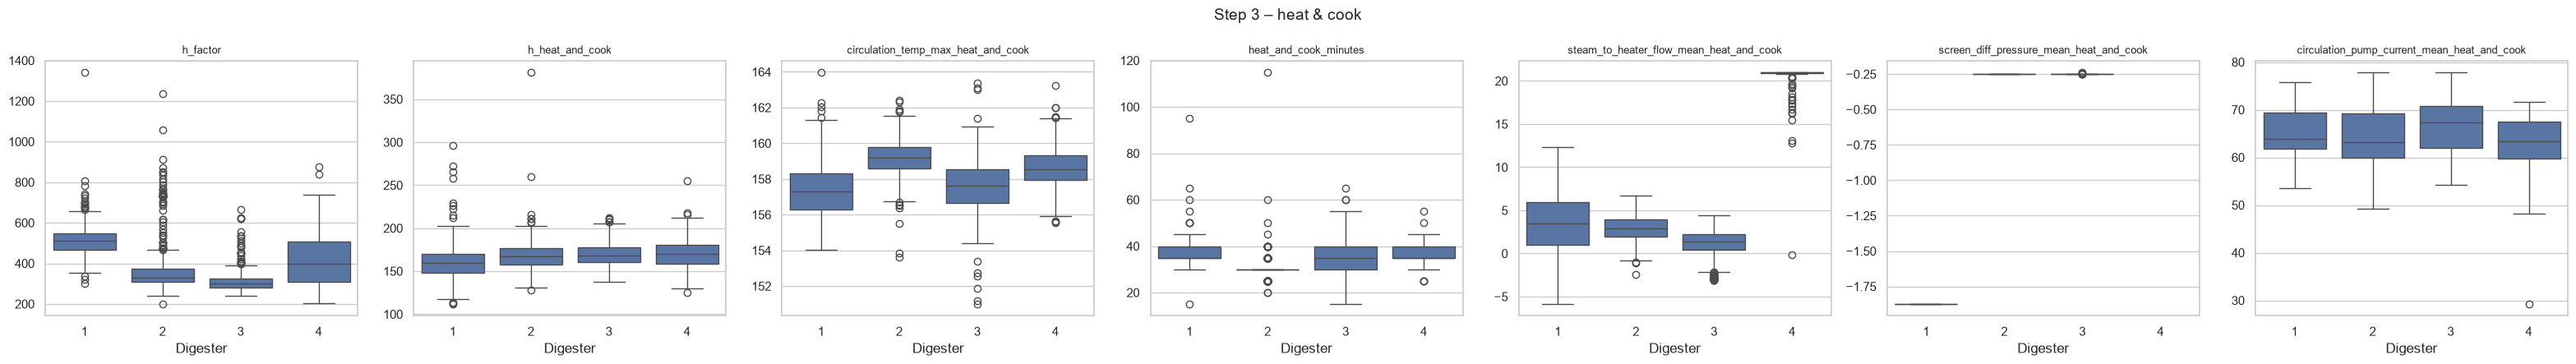

In [68]:
STEP3 = ["h_factor", "h_heat_and_cook", "circulation_temp_max_heat_and_cook", "heat_and_cook_minutes",
         "steam_to_heater_flow_mean_heat_and_cook", "screen_diff_pressure_mean_heat_and_cook",
         "circulation_pump_current_mean_heat_and_cook"]
display(volatility_table(STEP3))
boxplots(STEP3, "Step 3 – heat & cook")

## Step 4 – Displacement

- `displacement_liquor_temp_mean_displacement`, `displacement_minutes`, `h_displacement` (cooking still going on)
- `black_liquor_conductivity_mean_displacement` (shared tag, residual-alkali proxy)

N    Mean     SD  \
Parameter                                   Digester                       
displacement_liquor_temp_mean_displacement  D1        413  134.70   5.95   
                                            D2        414  132.20   5.12   
                                            D3        408  137.47   7.25   
                                            D4        228  134.51   6.02   
displacement_minutes                        D1        413   35.05  16.12   
                                            D2        414   29.78  14.14   
                                            D3        408   35.66   8.13   
                                            D4        228   37.65  22.04   
h_displacement                              D1        413   93.65  53.25   
                                            D2        414   96.84  43.16   
                                            D3        408   89.16  30.94   
                                            D4        228   80.43  39.19   
black_liquor_conductivity_mean_displacement D1        413   52.65  12.38   
                                            D2        414   53.81  17.69   
                                            D3        408   52.94  14.48   
                                            D4        228   51.33   9.56   

                                                        CV%     Min     Max  
Parameter                                   Digester                         
displacement_liquor_temp_mean_displacement  D1         4.41  111.64  147.88  
                                            D2         3.87  118.92  149.49  
                                            D3         5.27  114.61  153.05  
                                            D4         4.48  116.83  149.37  
displacement_minutes                        D1        45.99   20.00  255.00  
                                            D2        47.46   15.00  230.00  
                                            D3        22.81   15.00  120.00  
                                            D4        58.52   25.00  335.00  
h_displacement                              D1        56.86   44.90  962.01  
                                            D2        44.57   28.26  672.41  
                                            D3        34.71   32.04  391.49  
                                            D4        48.73   29.87  285.84  
black_liquor_conductivity_mean_displacement D1        23.52   48.98  125.97  
                                            D2        32.87   48.98  152.56  
                                            D3        27.36   48.98  151.53  
                                            D4        18.63   48.98  124.98

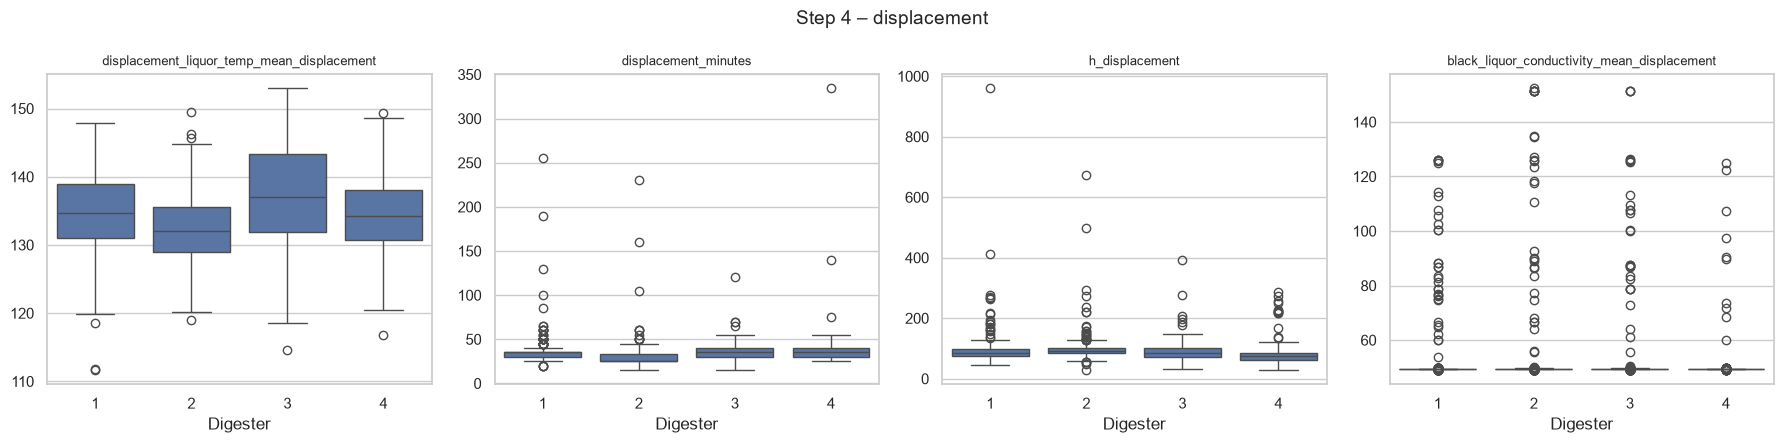

In [69]:
STEP4 = ["displacement_liquor_temp_mean_displacement", "displacement_minutes", "h_displacement",
         "black_liquor_conductivity_mean_displacement"]
display(volatility_table(STEP4))
boxplots(STEP4, "Step 4 – displacement")

## Phase 4 – Link to lab: which batch values go with Press 1 quality?

Only batches with a lab value. Spearman correlation per digester (rows = batch values, columns = lab).
Rough guide with ~60–85 batches per digester: |r| < 0.25 is likely noise.

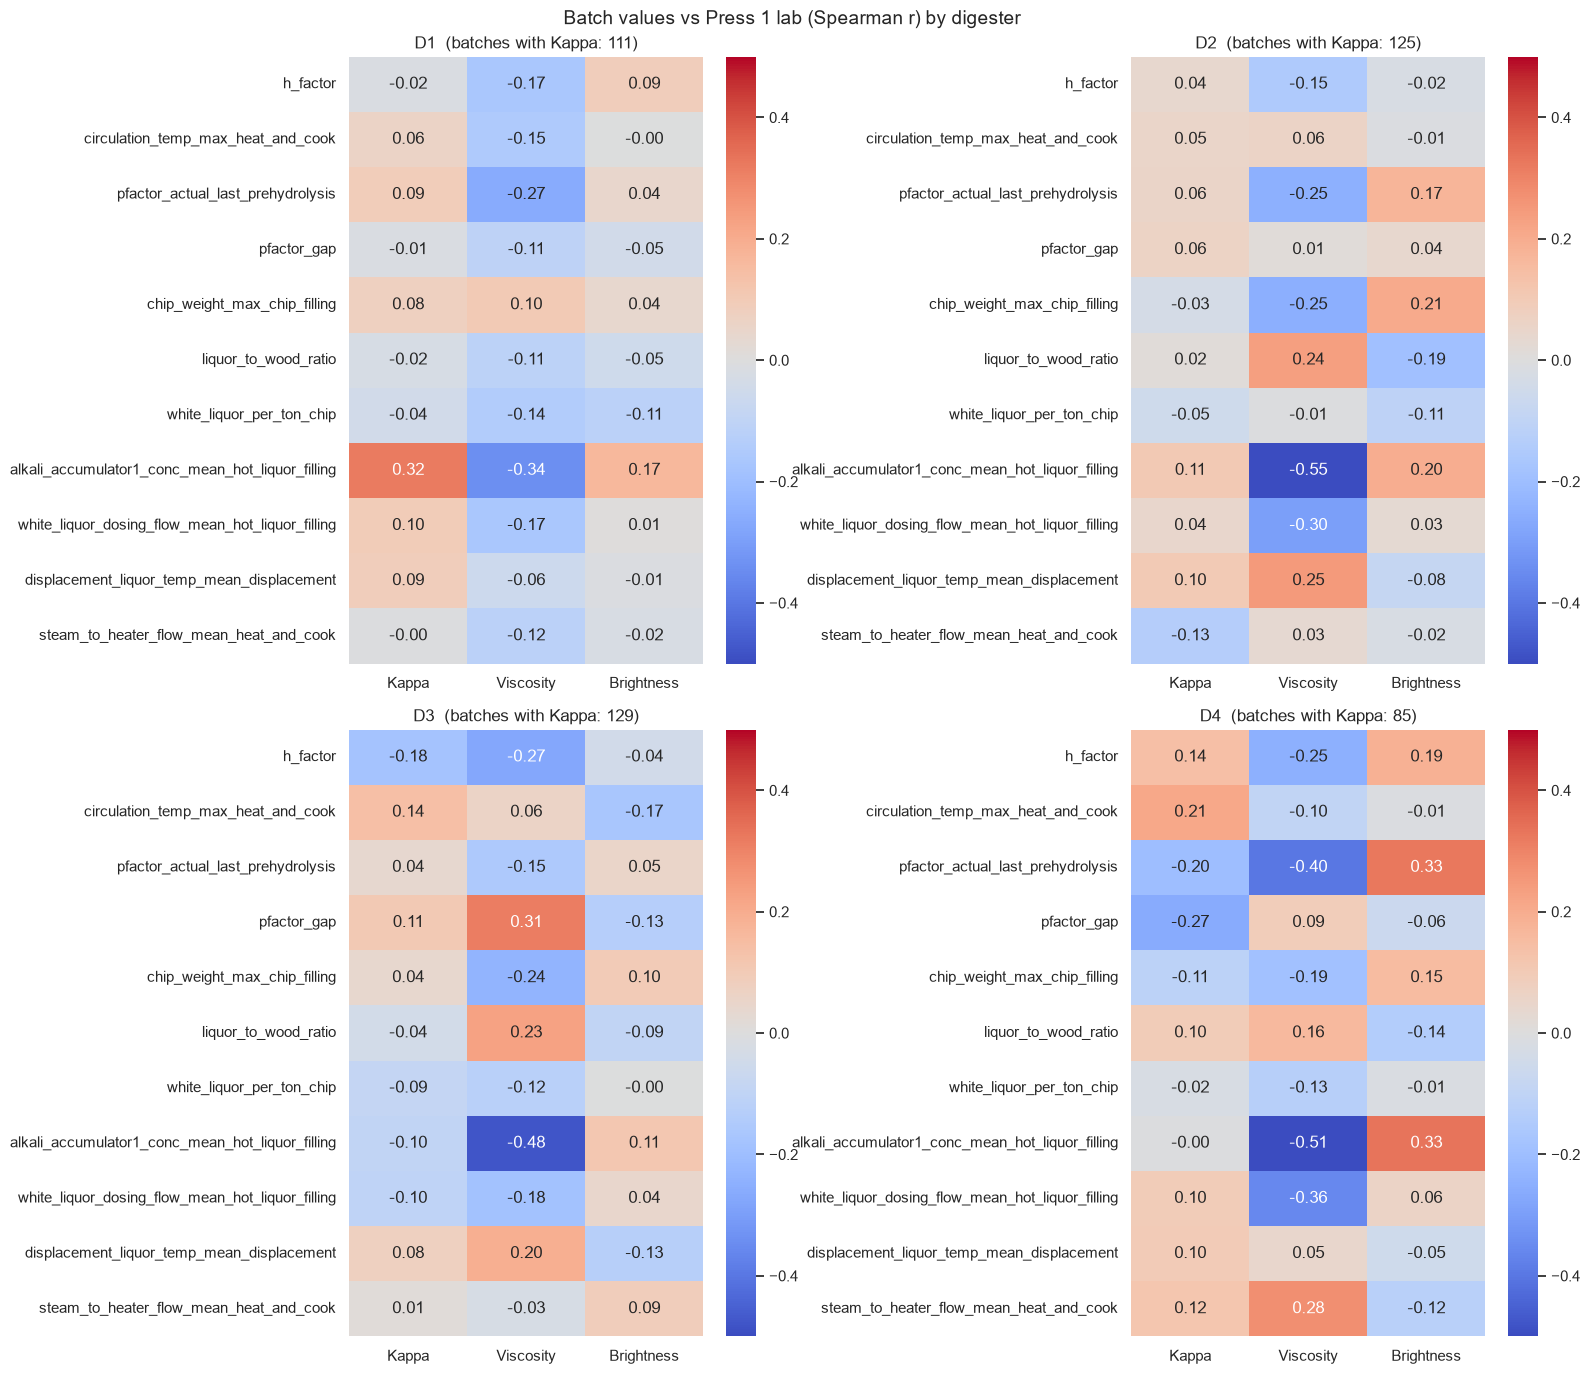

In [70]:
X_COLUMNS = ["h_factor",
             "circulation_temp_max_heat_and_cook", "pfactor_actual_last_prehydrolysis", "pfactor_gap",
             "chip_weight_max_chip_filling", "liquor_to_wood_ratio", "white_liquor_per_ton_chip",
             "alkali_accumulator1_conc_mean_hot_liquor_filling", "white_liquor_dosing_flow_mean_hot_liquor_filling",
             "displacement_liquor_temp_mean_displacement","steam_to_heater_flow_mean_heat_and_cook"]
X_COLUMNS = [c for c in X_COLUMNS if c in master]
CORR_LIMIT = 0.5

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for ax, dig in zip(axes.flatten(), [1, 2, 3, 4]):
    d = master[master["digester"] == dig]
    corr = pd.DataFrame({label: [d[x].corr(d[param], method="spearman") for x in X_COLUMNS]
                         for param, label in LAB_LABELS.items()}, index=X_COLUMNS)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-CORR_LIMIT, vmax=CORR_LIMIT, ax=ax)
    ax.set_title(f"D{dig}  (batches with Kappa: {d['press1_kappa'].notna().sum()})")
plt.suptitle("Batch values vs Press 1 lab (Spearman r) by digester", fontsize=14)
plt.tight_layout()
plt.show()

### White liquor per ton of chips vs Kappa

H-factor uses only temperature and time – it does not see how many tons of chips are in the digester.
The white liquor volume looks like a fixed recipe, so a batch with fewer chips gets **more alkali per ton**.
Expected: dots going down to the right (more white liquor per ton → lower Kappa).

⚠️ Chip weight is **wet** (moisture tag not usable) and the white liquor tag is shared (read only while this digester is in HOT LIQUOR FILLING).
D4 is a newer digester, its volume may differ – compare D4 with itself only.


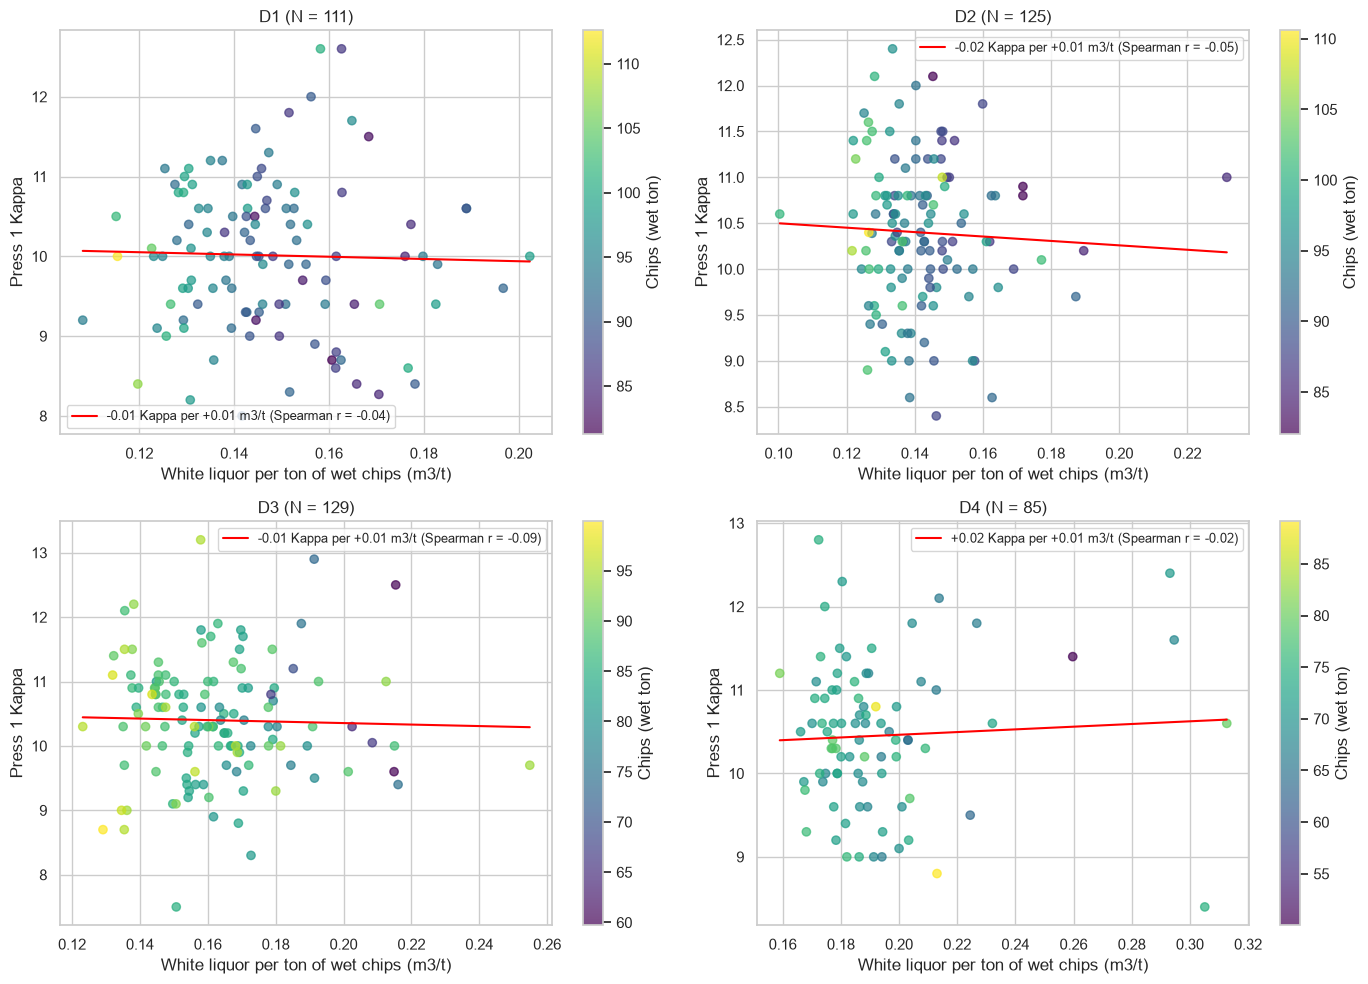

chip_weight_max_chip_filling        white_liquor_m3         \
                               median    std          median    std   
digester                                                              
1                              92.828  5.908          13.053  1.726   
2                              93.342  5.581          12.989  1.345   
3                              86.100  6.868          13.161  1.772   
4                              71.563  5.109          12.989  1.811   

         white_liquor_per_ton_chip         
                            median    std  
digester                                   
1                            0.145  0.021  
2                            0.141  0.016  
3                            0.159  0.023  
4                            0.187  0.027

digester
1   -0.07
2   -0.07
3    0.01
4    0.18
Name: Spearman r: white liquor m3 vs chip weight (≈ 0 = not adjusted to chips), dtype: float64

In [71]:
wk = master.dropna(subset=["white_liquor_per_ton_chip", "press1_kappa"])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, dig in zip(axes.flatten(), [1, 2, 3, 4]):
    d = wk[wk["digester"] == dig]
    points = ax.scatter(d["white_liquor_per_ton_chip"], d["press1_kappa"], c=d["chip_weight_max_chip_filling"],
                        cmap="viridis", alpha=0.7)
    fig.colorbar(points, ax=ax, label="Chips (wet ton)")
    if len(d) >= 5:
        slope, intercept = np.polyfit(d["white_liquor_per_ton_chip"], d["press1_kappa"], 1)
        x = np.linspace(d["white_liquor_per_ton_chip"].min(), d["white_liquor_per_ton_chip"].max(), 50)
        r = d["white_liquor_per_ton_chip"].corr(d["press1_kappa"], method="spearman")
        ax.plot(x, slope * x + intercept, color="red",
                label=f"{slope * 0.01:+.2f} Kappa per +0.01 m3/t (Spearman r = {r:.2f})")
        ax.legend(fontsize=9)
    ax.set_title(f"D{dig} (N = {len(d)})")
    ax.set_xlabel("White liquor per ton of wet chips (m3/t)")
    ax.set_ylabel("Press 1 Kappa")
plt.tight_layout()
plt.show()

# Is the white liquor volume really fixed? (small SD = fixed recipe, not adjusted to the chip weight)
display(master.groupby("digester")[["chip_weight_max_chip_filling", "white_liquor_m3", "white_liquor_per_ton_chip"]]
        .agg(["median", "std"]).round(3))
display(master.groupby("digester").apply(
    lambda d: d["white_liquor_m3"].corr(d["chip_weight_max_chip_filling"], method="spearman"))
        .round(2).rename("Spearman r: white liquor m3 vs chip weight (≈ 0 = not adjusted to chips)"))


### Accumulator 1 alkali (`PM2.404AIC670`) vs Press 1 Viscosity – 2-sigma filtered

- X = `alkali_accumulator1_conc_mean_hot_liquor_filling`: mean g/l while **this digester** fills hot liquor (shared tag)
- Y = `press1_viscosity`: real log book samples linked to the **same batch** (not the PI-interpolated tag)
- Filter per digester: drop a batch when X **or** Y is outside mean ± `SIGMA` × SD of that digester
- Colour = batch date. ⚠️ Both values drift over Aug–Sep (alkali up, viscosity down): if the colours form separate groups, the slope is mostly a time trend, not a batch-to-batch effect.


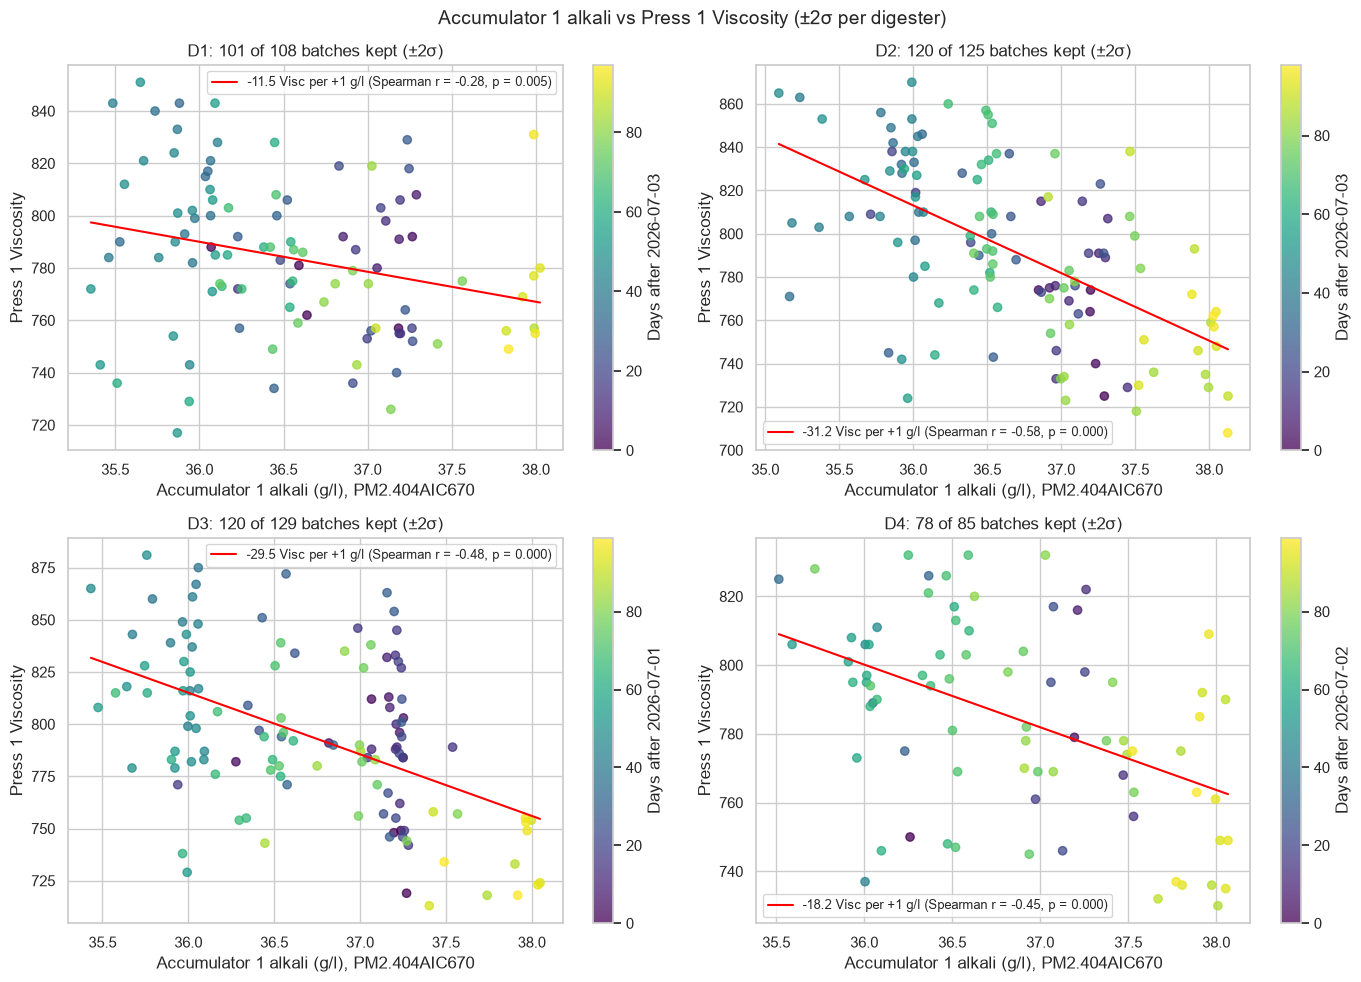

,Digester,N before,N after,Removed,X mean,Y mean,Spearman r,p-value
0,D1,108,101,7,36.557,783.644,-0.276,0.005
1,D2,125,120,5,36.660,792.458,-0.584,0.000
2,D3,129,120,9,36.722,793.758,-0.476,0.000
3,D4,85,78,7,36.850,784.641,-0.447,0.000


In [72]:
from scipy.stats import spearmanr

SIGMA = 2
X_COL, X_LABEL = "alkali_accumulator1_conc_mean_hot_liquor_filling", "Accumulator 1 alkali (g/l), PM2.404AIC670"
Y_COL, Y_LABEL = "press1_viscosity", "Press 1 Viscosity"


def within_sigma(values, sigma):
    return (values - values.mean()).abs() <= sigma * values.std()


av = master.dropna(subset=[X_COL, Y_COL])
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
rows = []
for ax, dig in zip(axes.flatten(), [1, 2, 3, 4]):
    d = av[av["digester"] == dig]
    keep = within_sigma(d[X_COL], SIGMA) & within_sigma(d[Y_COL], SIGMA)
    kept = d[keep]
    days = (kept["batch_start"] - kept["batch_start"].min()).dt.days
    points = ax.scatter(kept[X_COL], kept[Y_COL], c=days, cmap="viridis", alpha=0.75)
    fig.colorbar(points, ax=ax, label=f"Days after {kept['batch_start'].min():%Y-%m-%d}")
    r, p = spearmanr(kept[X_COL], kept[Y_COL]) if len(kept) >= 5 else (np.nan, np.nan)
    if len(kept) >= 5:
        slope, intercept = np.polyfit(kept[X_COL], kept[Y_COL], 1)
        x = np.linspace(kept[X_COL].min(), kept[X_COL].max(), 50)
        ax.plot(x, slope * x + intercept, color="red",
                label=f"{slope:+.1f} Visc per +1 g/l (Spearman r = {r:.2f}, p = {p:.3f})")
        ax.legend(fontsize=9)
    ax.set_title(f"D{dig}: {len(kept)} of {len(d)} batches kept (±{SIGMA}σ)")
    ax.set_xlabel(X_LABEL)
    ax.set_ylabel(Y_LABEL)
    rows.append({"Digester": f"D{dig}", "N before": len(d), "N after": len(kept), "Removed": len(d) - len(kept),
                 "X mean": kept[X_COL].mean(), "Y mean": kept[Y_COL].mean(), "Spearman r": r, "p-value": p})
fig.suptitle(f"Accumulator 1 alkali vs Press 1 Viscosity (±{SIGMA}σ per digester)", fontsize=14)
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).round(3))


### P-factor vs Press 1 Viscosity, per digester

Scatter of prehydrolysis P-factor (`pfactor_actual_last_prehydrolysis`) against Press 1 Viscosity, one panel per digester. 
Same style as the alkali chart: outliers beyond ±σ on either axis are dropped, points are coloured by batch date, and the red line is an OLS fit with the Spearman r / p. 
No lag/production adjustment — a *hypothesis*, not a finding.

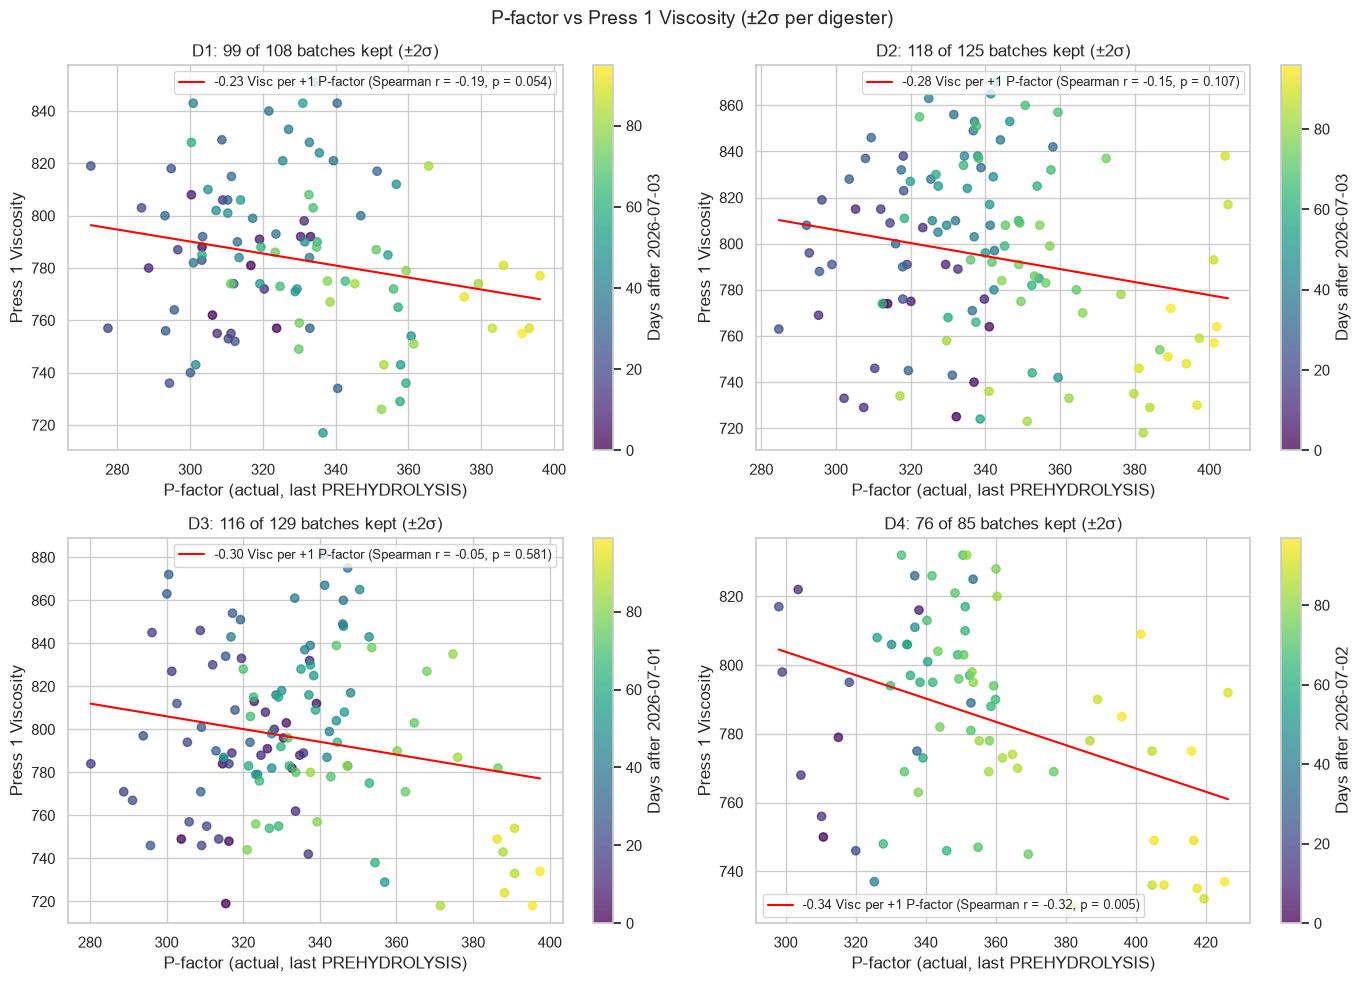

,Digester,N before,N after,Removed,X mean,Y mean,Spearman r,p-value
0,D1,108,99,9,328.001,783.707,-0.194,0.054
1,D2,125,118,7,340.250,794.593,-0.149,0.107
2,D3,129,116,13,333.330,796.190,-0.052,0.581
3,D4,85,76,9,354.463,785.395,-0.320,0.005


In [73]:
from scipy.stats import spearmanr

SIGMA = 2
X_COL, X_LABEL = "pfactor_actual_last_prehydrolysis", "P-factor (actual, last PREHYDROLYSIS)"
Y_COL, Y_LABEL = "press1_viscosity", "Press 1 Viscosity"


def within_sigma(values, sigma):
    return (values - values.mean()).abs() <= sigma * values.std()


av = master.dropna(subset=[X_COL, Y_COL])
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
rows = []
for ax, dig in zip(axes.flatten(), [1, 2, 3, 4]):
    d = av[av["digester"] == dig]
    keep = within_sigma(d[X_COL], SIGMA) & within_sigma(d[Y_COL], SIGMA)
    kept = d[keep]
    days = (kept["batch_start"] - kept["batch_start"].min()).dt.days
    points = ax.scatter(kept[X_COL], kept[Y_COL], c=days, cmap="viridis", alpha=0.75)
    fig.colorbar(points, ax=ax, label=f"Days after {kept['batch_start'].min():%Y-%m-%d}")
    r, p = spearmanr(kept[X_COL], kept[Y_COL]) if len(kept) >= 5 else (np.nan, np.nan)
    if len(kept) >= 5:
        slope, intercept = np.polyfit(kept[X_COL], kept[Y_COL], 1)
        x = np.linspace(kept[X_COL].min(), kept[X_COL].max(), 50)
        ax.plot(x, slope * x + intercept, color="red",
                label=f"{slope:+.2f} Visc per +1 P-factor (Spearman r = {r:.2f}, p = {p:.3f})")
        ax.legend(fontsize=9)
    ax.set_title(f"D{dig}: {len(kept)} of {len(d)} batches kept (±{SIGMA}σ)")
    ax.set_xlabel(X_LABEL)
    ax.set_ylabel(Y_LABEL)
    rows.append({"Digester": f"D{dig}", "N before": len(d), "N after": len(kept), "Removed": len(d) - len(kept),
                 "X mean": kept[X_COL].mean(), "Y mean": kept[Y_COL].mean(), "Spearman r": r, "p-value": p})
fig.suptitle(f"P-factor vs Press 1 Viscosity (±{SIGMA}σ per digester)", fontsize=14)
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).round(3))

## Pareto Front Analysis: Golden Batch Discovery

Find the optimal trade-off curve between Kappa (minimize) and Viscosity (maximize).
Uses 2-sigma filtering to remove outliers, then identifies the ideal point on Pareto front.

**Approach:**
- Q1: Kappa and Viscosity weighted equally
- Q2: Ideal point found automatically as closest to utopia (min Kappa, max Viscosity)
- Q3: Outliers removed by 2-sigma filter per variable

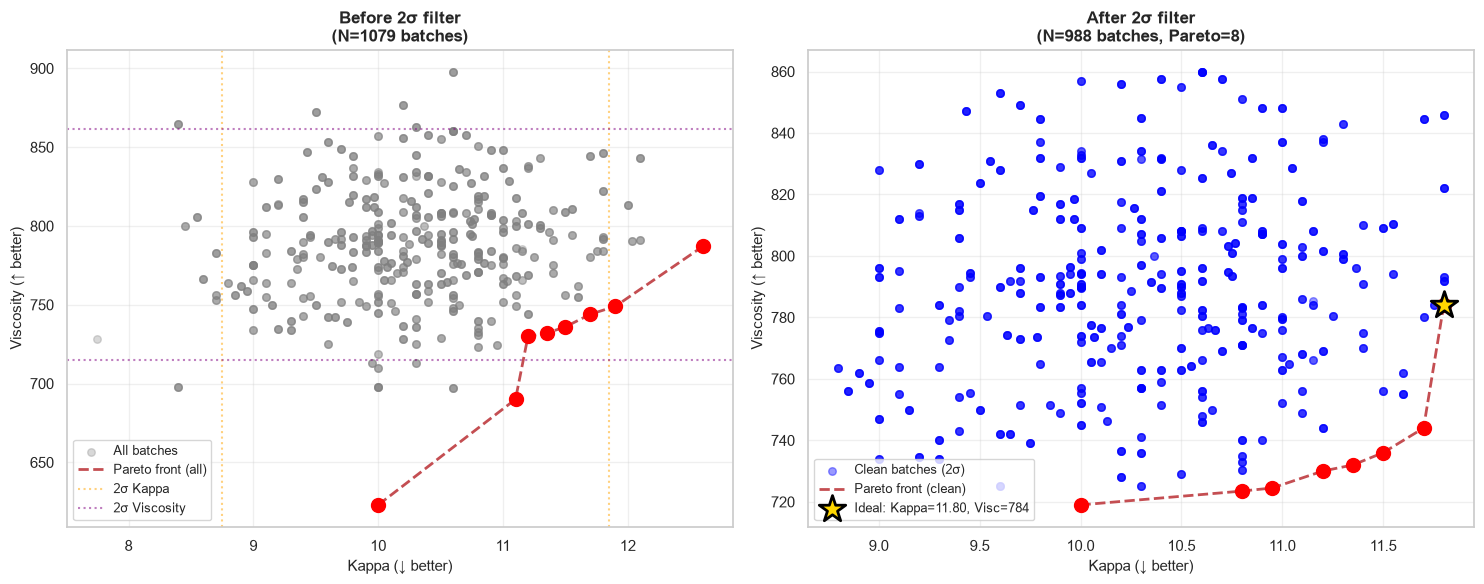


PARETO FRONT ANALYSIS RESULTS

Filtering by 2-sigma:
  Kappa: 10.30 ± 0.78 → [8.75, 11.85]
  Viscosity: 788 ± 37 → [715, 862]
  Removed: 91 outliers
  Kept: 988 batches

Pareto front (clean data):
  Points on front: 8
  Kappa range: 10.00 – 11.80
  Viscosity range: 719 – 784

Ideal point (closest to utopia):
  Kappa: 11.80
  Viscosity: 784
  Digester: D1

Golden batches (within 5% of ideal):
  Count: 16
  Kappa: 11.77 ± 0.04
  Viscosity: 787 ± 5
  By digester:
digester
1    5
2    5
3    5
4    1
dtype: int64




In [74]:
from pareto_golden_batch import analyze_pareto

# Run Pareto front analysis
results = analyze_pareto(master, lab_linked, save_path='image/pareto_golden_batch.png')

# Inspect golden batches by digester
golden = results['golden_batches']